# Modelo de compra con presupuesto: minimizar el faltante esperado (Fase 1)

Para cada polígono $p$ se resuelve

$$\min_{q^I,q^R}\ \sum_{e\in E} w_e\,\mathbb{E}\big[F_{e,p}\big],\qquad F_{e,p}=\max\{0,\,D_{e,p}-X_{e,p}-Z_{e,p}\}$$

sujeto a: presupuesto $\sum_e c_e(q^I_{e,p}+q^R_{e,p})\le B\,A_p$ (3), capacidad $\sum_e q^I_{e,p}\le\mathbb{E}[L_p]$ (4), tope $q^I_{e,p}\le\max\{0,(1+\delta)D_{e,p}-\mathbb{E}[X_{e,p}]\}$ (5), $q^R_{e,p}\le q^I_{e,p}$ (6) y enteros (7).
Desaparece $h_e$: el costo de compra solo entra por el presupuesto.

**Criterios (pesos $w_e$)**: el modelo no dice cómo comparar faltantes de especies distintas, y eso cambia mucho la solución:

| Criterio | Qué minimiza |
|---|---|
| `plantas` | $\sum_e \mathbb{E}[F_e]$: plantas faltantes totales ($w_e=1$) |
| `fraccion` | $\sum_e \mathbb{E}[F_e]/D_e$: fracción faltante de la meta de cada especie ($w_e=1/D_e$) |
| `equilibrado` | maximiza la cobertura mínima entre especies: siempre se compra para la especie con menor cobertura $1-\mathbb{E}[F_e]/D_e$ |

**Método.** $X$ (modelo B: Bin$(x,0.95)$) y $Z$ (secuencial) se simulan con números aleatorios comunes: un flujo de Bernoulli($S_e$) por planta, de modo que $Z$ es monótona en $q^I$ y $q^R$. Como $F_e$ solo depende de las compras de la especie $e$, un algoritmo voraz compra, una planta a la vez, la opción con mayor reducción del objetivo por peso gastado y solo reevalúa la especie que cambió. A igualdad de beneficio se prefiere sembrar ($q^I$) antes que reponer ($q^R$). La solución se valida **fuera de muestra** con escenarios nuevos.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- CONFIGURACIÓN ----------------
N_OPT, N_VAL, SEED = 10_000, 20_000, 2026
ERR_REG  = 0.05       # modelo B: prob. de que una planta registrada ya no exista
B_HA     = 12_500     # presupuesto por hectárea ($)
PTOS_HA  = 658        # PLACEHOLDER: |N_p| = round(658 * A_p) hasta tener la malla real
DELTA    = 0.05       # variación permitida por especie, restricción (5)
PREF_R   = 0.99       # desempate: a igualdad se prefiere sembrar antes que reponer
SUPERV   = 'sobrev_2023'   # supervivencia a 2 años

# ---------------- DATOS ----------------
datos = pd.read_csv('datos_limpios.csv')
par   = pd.read_csv('parametros_especies.csv').set_index('especie')
esp   = list(par.index)
x     = datos.pivot(index='especie', columns='poligono', values='plantas').loc[esp]
A     = datos.drop_duplicates('poligono').set_index('poligono')['area_ha'].sort_index()
x     = x[A.index]
E_, P_ = x.shape
d = par['meta_plantas_ha'].values.astype(float)
c = par['costo_c'].values.astype(float)
S = par[SUPERV].values.astype(float)
D = np.outer(d, A.values)                       # D_{e,p} = d_e * A_p
Np = np.round(PTOS_HA * A.values).astype(int)   # puntos de malla por polígono

def simular_X(n, rng):
    return rng.binomial(x.values, 1 - ERR_REG, size=(n, E_, P_))

X = simular_X(N_OPT, np.random.default_rng(SEED))
print('X:', X.shape, '| presupuesto total: $', f'{B_HA*A.sum():,.0f}', '| meta total:', f'{D.sum():,.0f}', 'plantas')

X: (10000, 10, 30) | presupuesto total: $ 2,287,625 | meta total: 120,421 plantas


## 1. Optimizador por polígono (voraz con números aleatorios comunes)

In [2]:
def optimizar_poligono(p, X, rng, criterio='plantas', delta=DELTA, debug=False):
    """Devuelve (qI, qR, info) para el polígono p (índice 0-based)."""
    n = X.shape[0]; idx = np.arange(n)
    EX    = X[:, :, p].mean(0)
    L     = np.maximum(Np[p] - X[:, :, p].sum(1), 0)
    slots = int(np.floor(L.mean()))                                        # restricción (4)
    U     = np.maximum(0, np.floor((1 + delta) * D[:, p] - EX)).astype(int)  # restricción (5)
    w     = 1.0 / D[:, p] if criterio == 'fraccion' else np.ones(E_)
    budget = B_HA * A.values[p]                                            # restricción (3)

    # flujos de Bernoulli por planta (números comunes): fila k = k-ésima planta
    B1 = [(rng.random((U[e], n)) < S[e]).astype(np.int8) for e in range(E_)]
    C2 = [np.vstack([np.zeros((1, n), np.int16),
                     np.cumsum(rng.random((U[e], n)) < S[e], axis=0, dtype=np.int16)]) for e in range(E_)]

    qI = np.zeros(E_, int); qR = np.zeros(E_, int)
    ZI = np.zeros((E_, n), np.int32); dead = np.zeros((E_, n), np.int32); ZR = np.zeros((E_, n), np.int32)
    Fcur = np.maximum(0.0, D[:, p, None] - X[:, :, p].T)                   # (10, n)
    Fm = Fcur.mean(1)

    def candidatos(e):
        # score = reducción ponderada de E[F_e] por peso gastado; [0]: +1 siembra, [1]: +1 reposición
        out = [-np.inf, -np.inf]; new = [None, None]
        if qI[e] < U[e]:
            zi = ZI[e] + B1[e][qI[e]]; dd = (qI[e] + 1) - zi
            zr = C2[e][np.minimum(qR[e], dd), idx]
            F2 = np.maximum(0.0, D[e, p] - X[:, e, p] - zi - zr)
            out[0] = w[e] * (Fm[e] - F2.mean()) / c[e]; new[0] = (zi, dd, zr, F2)
        if qR[e] < qI[e]:                                                   # restricción (6)
            zr = C2[e][np.minimum(qR[e] + 1, dead[e]), idx]                 # solo en cepas donde murió una planta
            F2 = np.maximum(0.0, D[e, p] - X[:, e, p] - ZI[e] - zr)
            out[1] = PREF_R * w[e] * (Fm[e] - F2.mean()) / c[e]; new[1] = (ZI[e], dead[e], zr, F2)
        return out, new

    sc = np.full((E_, 2), -np.inf); nw = [[None, None] for _ in range(E_)]
    for e in range(E_):
        sc[e], nw[e] = candidatos(e)
    left, slots_left = budget, slots
    while True:
        if criterio == 'equilibrado':
            ok = sc.max(1) > 1e-12
            if not ok.any(): break
            cob = np.where(ok, 1 - Fm / D[:, p], np.inf)                    # cobertura actual por especie
            e = int(np.argmin(cob)); t = int(np.argmax(sc[e]))
        else:
            e, t = divmod(int(np.argmax(sc)), 2)
            if sc[e, t] <= 1e-12: break
        if c[e] > left:               sc[e] = -np.inf; continue             # ya no alcanza el presupuesto
        if t == 0 and slots_left <= 0: sc[e, 0] = -np.inf; continue          # sin puntos libres en la malla
        zi, dd, zr, F2 = nw[e][t]
        if t == 0: qI[e] += 1; slots_left -= 1
        else:      qR[e] += 1
        ZI[e], dead[e], ZR[e] = zi, dd, zr; Fcur[e] = F2; Fm[e] = F2.mean(); left -= c[e]
        sc[e], nw[e] = candidatos(e)

    info = dict(gasto=budget - left, presupuesto=budget, slots=slots - slots_left, slots_disp=slots, U=U, EF=Fm.copy())
    if debug: info.update(B1=B1, C2=C2, w=w, Xp=X[:, :, p], p=p)
    return qI, qR, info

def resolver_todos(criterio, delta=DELTA, X=X):
    QI = np.zeros((E_, P_), int); QR = np.zeros((E_, P_), int); infos = []
    for p in range(P_):
        qi, qr, info = optimizar_poligono(p, X, np.random.default_rng(1000 + p), criterio, delta)
        QI[:, p], QR[:, p] = qi, qr; infos.append(info)
    return QI, QR, infos

## 2. Verificaciones del optimizador (polígono 5, criterio `plantas`)

(a) Contabilidad: $\mathbb{E}[F_e]$ recalculada desde cero con los flujos coincide con la que lleva el algoritmo.
(b) Optimalidad local: mover dinero entre pares de especies (1 % o 3 % de las siembras) no mejora el objetivo.

In [3]:
p = 4; n = N_OPT; idx = np.arange(n)
qI, qR, info = optimizar_poligono(p, X, np.random.default_rng(1000 + p), 'plantas', DELTA, debug=True)

def Feval(e, qi, qr):
    zi = info['B1'][e][:qi].sum(0, dtype=np.int32) if qi > 0 else np.zeros(n, np.int32)
    zr = info['C2'][e][np.minimum(qr, qi - zi), idx]
    return np.maximum(0.0, D[e, p] - info['Xp'][:, e] - zi - zr).mean()

err = max(abs(Feval(e, qI[e], qR[e]) - info['EF'][e]) for e in range(E_))
print(f'(a) máx |E[F] recalculada - E[F] del algoritmo| = {err:.2e}')

base = sum(Feval(e, qI[e], qR[e]) for e in range(E_)); mejor = 0.0
for a in range(E_):
    for b in range(E_):
        if a == b: continue
        for frac in (0.01, 0.03):
            m = max(1, int(frac * qI[a]))
            if qI[a] < m: continue
            qa = qI[a] - m; ra = min(qR[a], qa)
            mb = int(c[a] * (m + qR[a] - ra) // c[b]); qb = qI[b] + mb
            if qb > info['U'][b]: continue
            nuevo = base - Feval(a, qI[a], qR[a]) - Feval(b, qI[b], qR[b]) + Feval(a, qa, ra) + Feval(b, qb, qR[b])
            mejor = min(mejor, nuevo - base)
print(f'(b) mejor cambio del objetivo con movimientos locales = {mejor:.3f} (≥ 0 ⇒ óptimo local); objetivo = {base:.1f} plantas')

(a) máx |E[F] recalculada - E[F] del algoritmo| = 0.00e+00
(b) mejor cambio del objetivo con movimientos locales = 0.000 (≥ 0 ⇒ óptimo local); objetivo = 538.9 plantas


## 3. Validación fuera de muestra y comparación de criterios

Cada política se evalúa con 20,000 escenarios **nuevos** de $X$ y $Z$ (simulación directa, sin los flujos usados para optimizar), para no contar el sesgo optimista de optimizar y evaluar con los mismos escenarios. La línea base compra la misma fracción de la brecha en todas las especies, hasta agotar el presupuesto.

In [4]:
def validar(QI, QR, n=N_VAL, seed=99):
    r = np.random.default_rng(seed)
    Xv = simular_X(n, r)
    ZI = r.binomial(QI, S[:, None], size=(n, E_, P_))
    ZR = r.binomial(np.minimum(QR, QI - ZI), S[:, None])
    Z  = ZI + ZR
    F  = np.maximum(0.0, D - Xv - Z)
    return Xv, Z, F

def resumen(QI, QR):
    Xv, Z, F = validar(QI, QR)
    t = pd.DataFrame({'meta': D.sum(1), 'E_X': Xv.mean(0).sum(1), 'E_Z': Z.mean(0).sum(1), 'E_F': F.mean(0).sum(1),
                      'q_siembra': QI.sum(1), 'q_reposicion': QR.sum(1), 'gasto': (c[:, None] * (QI + QR)).sum(1)}, index=esp)
    t['cobertura_%'] = 100 * (1 - t.E_F / t.meta)
    return t

def politica_base(X=X, delta=DELTA):
    EX = X.mean(0)
    U = np.maximum(0, np.floor((1 + delta) * D - EX))
    need = np.minimum(U, np.ceil(np.maximum(D - EX, 0) / S[:, None]))
    QI = np.zeros((E_, P_), int)
    for p in range(P_):
        lo, hi = 0.0, 1.0
        for _ in range(40):
            k = (lo + hi) / 2
            if (c * np.floor(k * need[:, p])).sum() <= B_HA * A.values[p]: lo = k
            else: hi = k
        QI[:, p] = np.floor(lo * need[:, p])
    return QI, np.zeros_like(QI)

politicas = {'base_uniforme': politica_base()}
for crit in ('plantas', 'fraccion', 'equilibrado'):
    t0 = time.time()
    QI, QR, infos = resolver_todos(crit)
    politicas[crit] = (QI, QR)
    print(f'{crit:12s} {time.time()-t0:4.0f} s | siembras en el tope (5): {sum(int((i["U"] <= q).sum()) for i, q in zip(infos, QI.T))} de 300 '
          f'| puntos de malla usados: {sum(i["slots"] for i in infos):,}/{sum(i["slots_disp"] for i in infos):,}')

tablas = {k: resumen(*v) for k, v in politicas.items()}
comp = pd.DataFrame({k: {
    'faltante esperado (plantas)': t.E_F.sum(),
    'faltante (% de la meta)': 100 * t.E_F.sum() / t.meta.sum(),
    'cobertura mínima por especie (%)': t['cobertura_%'].min(),
    'especie menos cubierta': t['cobertura_%'].idxmin(),
    'gasto ($)': t.gasto.sum(),
    'plantas compradas': (t.q_siembra + t.q_reposicion).sum()} for k, t in tablas.items()}).T
comp

plantas        43 s | siembras en el tope (5): 229 de 300 | puntos de malla usados: 93,257/98,017


fraccion       43 s | siembras en el tope (5): 270 de 300 | puntos de malla usados: 89,100/98,017


equilibrado    48 s | siembras en el tope (5): 64 de 300 | puntos de malla usados: 95,624/98,017


,faltante esperado (plantas),faltante (% de la meta),cobertura mínima por especie (%),especie menos cubierta,gasto ($),plantas compradas
base_uniforme,13950.927789,11.585169,76.859164,Yucca filifera,2287225.5,97180
plantas,11673.805202,9.694194,18.206467,Yucca filifera,2287376.0,98625
fraccion,14939.448345,12.406059,59.620817,Agave salmiana,2287421.0,98895
equilibrado,14434.524449,11.986759,87.936544,Agave salmiana,2287364.0,97114


,base_uniforme,plantas,fraccion,equilibrado
Agave lechuguilla,93.2,98.4,99.8,88.1
Agave salmiana,92.0,99.1,59.6,87.9
Agave scabra,78.5,19.6,98.6,88.1
Agave striata,92.1,98.2,99.8,88.1
Opuntia cantabrigiensis,85.6,98.7,99.8,88.1
Opuntia engelmannii,84.9,97.9,99.7,88.1
Opuntia robusta,93.0,99.3,99.8,88.0
Opuntia streptacantha,87.4,99.0,99.7,88.0
Prosopis laevigata,84.5,96.5,99.3,88.0
Yucca filifera,76.9,18.2,97.8,88.1


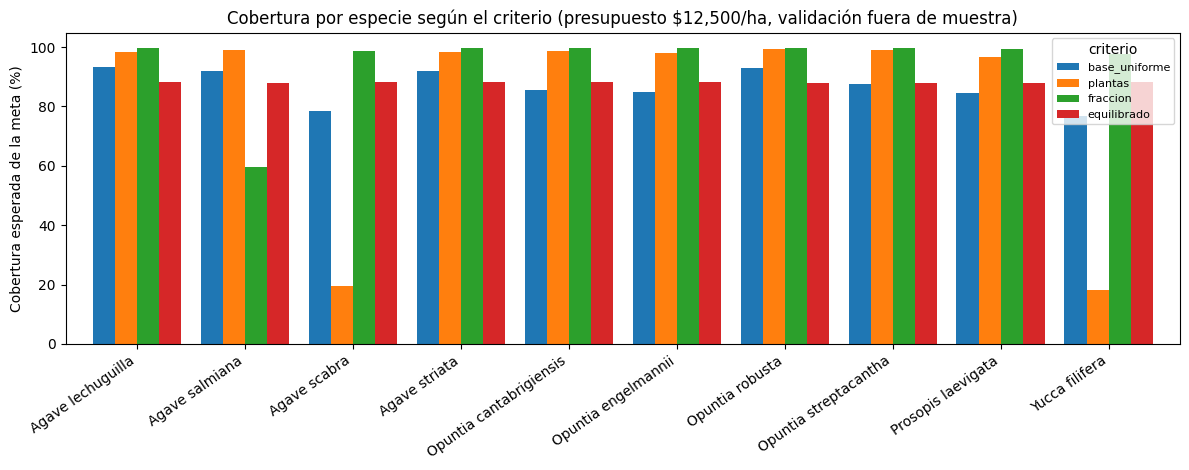

In [5]:
cob = pd.DataFrame({k: t['cobertura_%'] for k, t in tablas.items()}).round(1)
display(cob)

ax = cob.plot.bar(figsize=(12, 4.8), width=0.82)
ax.set_ylabel('Cobertura esperada de la meta (%)'); ax.set_xlabel('')
ax.set_title(f'Cobertura por especie según el criterio (presupuesto ${B_HA:,}/ha, validación fuera de muestra)')
plt.xticks(rotation=35, ha='right'); plt.legend(title='criterio', fontsize=8); plt.tight_layout(); plt.show()

## 4. Sensibilidad a $\delta$ (restricción 5)
Si el presupuesto es lo que limita, cambiar $\delta$ de 5 % a 10 % no debería cambiar el resultado.

In [6]:
filas = []
for crit in ('plantas', 'equilibrado'):
    for dl in (0.05, 0.10):
        QI, QR, infos = resolver_todos(crit, dl) if dl != DELTA else (*politicas[crit], None)
        t = resumen(QI, QR)
        filas.append((crit, dl, t.E_F.sum(), t['cobertura_%'].min(), t.gasto.sum()))
pd.DataFrame(filas, columns=['criterio', 'delta', 'faltante_esperado', 'cobertura_min_%', 'gasto']).round({'faltante_esperado': 1, 'cobertura_min_%': 1, 'gasto': 0})

,criterio,delta,faltante_esperado,cobertura_min_%,gasto
0,plantas,0.05,11673.8,18.2,2287376.0
1,plantas,0.10,11673.5,18.2,2287374.0
2,equilibrado,0.05,14434.5,87.9,2287364.0
3,equilibrado,0.10,14433.7,87.9,2287374.0


## 5. Plan de compra por polígono y especie

In [7]:
filas = []
for crit in ('plantas', 'fraccion', 'equilibrado'):
    QI, QR = politicas[crit]
    for j, pol in enumerate(A.index):
        for i, e in enumerate(esp):
            filas.append((crit, pol, A.values[j], e, QI[i, j], QR[i, j], QI[i, j] + QR[i, j], c[i] * (QI[i, j] + QR[i, j])))
plan = pd.DataFrame(filas, columns=['criterio', 'poligono', 'area_ha', 'especie', 'q_siembra', 'q_reposicion', 'q_total', 'costo'])
plan.to_csv('plan_compra.csv', index=False)
print(plan.shape)
plan.query("criterio == 'equilibrado' and poligono == 1")

(900, 8)


,criterio,poligono,area_ha,especie,q_siembra,q_reposicion,q_total,costo
600,equilibrado,1,1.28,Agave lechuguilla,43,0,43,1118.0
601,equilibrado,1,1.28,Agave salmiana,195,0,195,5070.0
602,equilibrado,1,1.28,Agave scabra,41,2,43,1118.0
603,equilibrado,1,1.28,Agave striata,36,0,36,936.0
604,equilibrado,1,1.28,Opuntia cantabrigiensis,54,0,54,972.0
605,equilibrado,1,1.28,Opuntia engelmannii,37,0,37,777.0
606,equilibrado,1,1.28,Opuntia robusta,70,1,71,1278.0
607,equilibrado,1,1.28,Opuntia streptacantha,71,1,72,1296.0
608,equilibrado,1,1.28,Prosopis laevigata,101,0,101,2676.5
609,equilibrado,1,1.28,Yucca filifera,26,3,29,754.0
